# GRU para formación de colas (CAETEC)

Escalera de experimentos para llegar a la GRU final y su evaluación en test, que predice `pct_posible_cola` del **mismo bloque de 30 min del día siguiente** (24 h adelante, `HORIZON = 48`) de cada robot. Es lo que se usa en el demo.

- **Predicción del día siguiente:** la ventana termina 24 h antes del bloque que se predice (ventana en *t−48*, objetivo en *t*). Con `HORIZON = 1` el notebook vuelve a predecir el siguiente bloque, como la versión anterior.
- **Línea base justa:** con 24 h de anticipación ya no se conoce el bloque anterior, así que la comparación es contra *siempre cola* y *mismo bloque ayer*.

- **Split cronológico 70 / 15 / 15**, se ordena el dataset por `bloque_tiempo` y `ms` y se corta por fila. Cada ventana se asigna al conjunto de su bloque objetivo, así el test tiene exactamente los mismos 26,978 bloques que los demás modelos.
- **Se entrena solo con train (70 %).** El imputer y el scaler se ajustan solo con train.
- **Todo se decide con validación (15 %):** early stopping, umbral de decisión y qué experimento gana. **El test no se toca** hasta el modelo final.
- Cada paso parte del ganador del anterior y cambia **una sola cosa** (Greff et al., 2017). Gana el F1 de validación más alto; si otro queda a menos de `TOL` de F1, se elige el **más simple** (menos parámetros).
- Hay cola si `pct_posible_cola > 0.5`.

| Paso | Qué se prueba | Opciones | Base |
|---|---|---|---|
| E0 | GRU mínima | 1×GRU(32) → Dense(1, sigmoid), ventana 12, sin dropout | Mansur et al. (2026); Das (2023) |
| E1 | Unidades | 32 / 64 / 128 | Wang et al. (2021) |
| E2 | Largo de ventana | 12 / 24 / 48 bloques | Das (2023); Hewamalage et al. (2021) |
| E3 | Regularización | dropout 0 / 0.2 / 0.3 | sobreajuste visto en LSTM y GRU v1 |
| E4 | Profundidad | + Dense(32) / + 2.ª GRU / ambas | Das (2023); Greff et al. (2017) |
| E5 | Normalización y dirección | + LayerNorm / Bi-GRU | versiones `norm` y `bi` |
| Ref | Modelo v1 | 64→32 + Dense(32), ventana 48, dropout 0.2 | GRU anterior con TimeSeriesSplit |

Los resultados se van guardando en `experimentos_gru.csv`. Si Colab se desconecta, al volver a correr el notebook los experimentos ya hechos se saltan.

## 1. Configuración

In [12]:
# ====== RUTAS (ajusta a tu Drive) ======
DATA_PATH = "/content/drive/MyDrive/Datos/Procesado/dataset_final_serie_tiempo.parquet"
MODELING_PARENT = "/content/modeling"
RESULTS_CSV = "/content/drive/MyDrive/Datos/Resultados/experimentos_gru_dia_siguiente.csv"   # tabla acumulada

# ====== REGLAS COMUNES ======
TARGET = "pct_posible_cola"
LABEL_THR = 0.5        # hay cola si pct_posible_cola > 0.5 (Diseño de Pruebas)
HORIZON = 48           # bloques de 30 min del mismo robot entre el final de la ventana y el objetivo
                       # 48 = mismo bloque del día siguiente (24 h) | 1 = siguiente bloque (versión anterior)
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15
EPOCHS = 50
PATIENCE = 5           # early stopping sobre val_loss, restaurando los mejores pesos
BATCH = 128
LR = 1e-3
SEED = 42
TOL = 0.005            # si dos experimentos quedan a menos de TOL de F1 en val, gana el más simple
QUICK = False          # True = 3 épocas por experimento, solo para probar que todo corre
RERUN = False          # True = vuelve a entrenar aunque el experimento ya esté en el CSV
VERBOSE = 2            # 0 = silencioso | 2 = una línea por época

## 2. Imports y datos

In [13]:
import sys, os, time, gc
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
# ---- Encontrar los módulos (modeling/gru/gru_model.py, modeling/tcn/tcn_model.py, modeling/model_base.py) ----
# Colab: se clona el repo (rama REPO_BRANCH). Local: se usa la carpeta del repo y data/ local.
REPO_URL = "https://github.com/kamimartinez/VMS-prediction.git"
REPO_BRANCH = "main"
NEEDED = ["gru/gru_model.py", "tcn/tcn_model.py", "model_base.py"]

def _has_files(notebooks_dir):
    return all(os.path.exists(os.path.join(notebooks_dir, "modeling", f)) for f in NEEDED)

if IN_COLAB:
    if not _has_files(MODELING_PARENT):
        os.system(f"rm -rf /content/vms && git clone -q -b {REPO_BRANCH} {REPO_URL} /content/vms")
        MODELING_PARENT = "/content/vms/notebooks"
else:
    from pathlib import Path
    REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "data").is_dir() and (p / "notebooks").is_dir())
    MODELING_PARENT = str(REPO_ROOT / "notebooks")
    DATA_PATH = str(REPO_ROOT / "data" / "dataset_final_serie_tiempo.parquet")
    RESULTS_CSV = str(REPO_ROOT / "notebooks" / "modeling" / "gru" / "experimentos_gru_dia_siguiente.csv")
if not _has_files(MODELING_PARENT):
    raise FileNotFoundError(f"Faltan {NEEDED} en {MODELING_PARENT}/modeling/")
for sub in ("", "gru", "tcn"):
    folder = os.path.join(MODELING_PARENT, "modeling", sub)
    if folder not in sys.path:
        sys.path.insert(0, folder)
if MODELING_PARENT not in sys.path:
    sys.path.insert(0, MODELING_PARENT)
print("Usando módulos de:", os.path.join(MODELING_PARENT, "modeling"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             mean_absolute_error, mean_squared_error, confusion_matrix)
from tensorflow.keras.callbacks import EarlyStopping

from gru_model import GRUModel

if not hasattr(GRUModel, "split_temporal"):
    raise ImportError("Esta versión de gru_model.py no tiene split_temporal; sube la versión nueva.")
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Usando módulos de: /content/vms/notebooks/modeling
TensorFlow 2.21.0 | GPU: []


In [14]:
df = pd.read_parquet(DATA_PATH)
df["temporada"] = df["temporada"].astype(object)   # prepare() espera texto tipo object
df["bloque_tiempo"] = pd.to_datetime(df["bloque_tiempo"])
print(df.shape)
df.head()

(179850, 24)


,ms,bloque_tiempo,total_ordenios,produccion_promedio,duracion_total_min,patadas_totales,desviaciones_leche_totales,ordenios_con_lavado,pct_primer_parto,pct_fresca,...,pct_ocupacion_robot,hubo_lavado,ordenios_otros_robots,hora,dia_semana,temporada,min_desde_alimento,vacas_activas_dia,sin_etapa,pct_posible_cola
0,VMS 3,2022-08-01 00:00:00,2,13.375,19.066667,0,0.0,0,0.0,0.0,...,0.635556,0,0,0,0,verano,570.0,31,1,1.000000
1,VMS 3,2022-08-01 00:30:00,1,21.470,6.366667,0,0.0,0,0.0,0.0,...,0.212222,0,0,0,0,verano,600.0,31,1,0.000000
2,VMS 1,2022-08-01 01:00:00,3,11.030,16.783333,0,0.0,0,0.0,0.0,...,0.559444,0,1,1,0,verano,630.0,31,1,0.666667
3,VMS 3,2022-08-01 01:00:00,1,16.690,6.650000,0,0.0,0,0.0,0.0,...,0.221667,0,3,1,0,verano,630.0,31,1,0.000000
4,VMS 1,2022-08-01 01:30:00,0,NaN,0.000000,0,0.0,0,0.0,0.0,...,0.000000,0,0,1,0,verano,660.0,31,1,0.000000


## 3. Split 70 / 15 / 15 y líneas base (paso 0)

Primero se revisa que el split por fila dé los mismos tamaños y fechas que *Diseño de Pruebas* (125,894 / 26,978 / 26,978) y que las referencias en test den lo mismo que en los demás modelos (**siempre cola F1 ≈ 0.730**, **bloque anterior F1 ≈ 0.667**). Si no coinciden, el test no es el mismo y hay que revisar antes de seguir.

In [15]:
# Split a nivel fila (sin ventanas) para verificar contra Diseño de Pruebas
_ref = GRUModel()
rows = df[["ms", "bloque_tiempo"]].reset_index(drop=True)
r_tr, r_va, r_te = _ref.split_temporal(df, rows, TRAIN_FRAC, VAL_FRAC)
print("Filas:", _ref.split_info_["filas"])
for name, idx in [("Train", r_tr), ("Val", r_va), ("Test", r_te)]:
    t = rows["bloque_tiempo"].iloc[idx]
    print(f"{name:<5} | {t.min()} -> {t.max()} | {len(idx):,} bloques")

Filas: {'train': 125894, 'val': 26978, 'test': 26978}
Train | 2022-08-01 00:00:00 -> 2024-12-22 07:00:00 | 125,894 bloques
Val   | 2024-12-22 07:00:00 -> 2025-06-27 15:30:00 | 26,978 bloques
Test  | 2025-06-27 15:30:00 -> 2025-12-31 23:30:00 | 26,978 bloques


In [16]:
def label(y):
    return (np.asarray(y, dtype=float) > LABEL_THR).astype(int)

def cola_metrics(y_true, y_pred_bin):
    yt = label(y_true); yp = np.asarray(y_pred_bin).astype(int)
    return {"F1": f1_score(yt, yp, zero_division=0),
            "Precision": precision_score(yt, yp, zero_division=0),
            "Recall": recall_score(yt, yp, zero_division=0),
            "pct_cola_real": yt.mean()}

# Persistencia: hay cola en t si la hubo en el bloque anterior (t-1) del mismo robot
d = df[["ms", "bloque_tiempo", TARGET]].copy()
d["__row__"] = np.arange(len(d))
d = d.sort_values(["ms", "bloque_tiempo"])
g = d.groupby("ms")
contiguo = (d["bloque_tiempo"] - g["bloque_tiempo"].shift(1)) == pd.Timedelta("30min")
d["prev"] = g[TARGET].shift(1).where(contiguo)
prev_by_row = d.set_index("__row__")["prev"]
# Mismo bloque ayer: hay cola en t si la hubo 48 bloques antes (24 h) en el mismo robot.
# Es la línea base justa para predecir el día siguiente.
contiguo_ayer = (d["bloque_tiempo"] - g["bloque_tiempo"].shift(48)) == pd.Timedelta("24h")
d["ayer"] = g[TARGET].shift(48).where(contiguo_ayer)
ayer_by_row = d.set_index("__row__")["ayer"]

# rows -> posición en df (rows viene de df.reset_index, así que el índice coincide)
def baselines(idx):
    y = rows.index[idx]
    y_true = df[TARGET].to_numpy()[y]
    prev = prev_by_row.loc[y].fillna(0).to_numpy()
    ayer = ayer_by_row.loc[y].fillna(0).to_numpy()
    return pd.DataFrame({
        "Siempre cola": cola_metrics(y_true, np.ones(len(y))),
        "Bloque anterior (solo comparable con HORIZON = 1)": cola_metrics(y_true, label(prev)),
        "Mismo bloque ayer": cola_metrics(y_true, label(ayer)),
    }).T

BASE_VAL, BASE_TEST = baselines(r_va), baselines(r_te)
print("--- Validación ---"); display(BASE_VAL.round(3))
print("--- Test (solo para verificar que es el mismo test) ---"); display(BASE_TEST.round(3))

--- Validación ---


,F1,Precision,Recall,pct_cola_real
Siempre cola,0.597,0.425,1.000,0.425
Bloque anterior (solo comparable con HORIZON = 1),0.497,0.497,0.497,0.425
Mismo bloque ayer,0.491,0.491,0.491,0.425


--- Test (solo para verificar que es el mismo test) ---


,F1,Precision,Recall,pct_cola_real
Siempre cola,0.730,0.575,1.000,0.575
Bloque anterior (solo comparable con HORIZON = 1),0.667,0.667,0.667,0.575
Mismo bloque ayer,0.650,0.650,0.649,0.575


## 4. Funciones de los experimentos

- `get_data(window)`: arma las ventanas por robot (ventana en *t−HORIZON*, objetivo en *t*), hace el split y escala con train. Guarda en memoria solo la ventana actual.
- `run_experiment(...)`: entrena una configuración, elige el umbral con mejor F1 en validación y guarda una fila en el CSV.
- `pick_best(ids)`: gana el F1 de val más alto; empates (< `TOL`) se rompen por menos parámetros.

In [17]:
_CACHE = {}

def get_data(window):
    if window in _CACHE:
        return _CACHE[window]
    _CACHE.clear(); gc.collect()
    prep = GRUModel(task="regression", window=window, threshold=LABEL_THR)
    X_seq, y_seq, meta = prep.prepare(df, df[TARGET], horizon=HORIZON)
    tr, va, te = prep.split_temporal(df, meta, TRAIN_FRAC, VAL_FRAC)
    X_tr, X_va, X_te = prep.scale(X_seq[tr], X_seq[va], X_seq[te])   # scaler ajustado SOLO con train
    del X_seq; gc.collect()
    _CACHE[window] = dict(prep=prep, X_tr=X_tr, X_va=X_va, X_te=X_te,
                          y_tr=y_seq[tr], y_va=y_seq[va], y_te=y_seq[te],
                          meta_va=meta.iloc[va].reset_index(drop=True),
                          meta_te=meta.iloc[te].reset_index(drop=True))
    print(f"Ventana {window} | horizonte {HORIZON}: train={len(tr):,} val={len(va):,} test={len(te):,} | features={X_tr.shape[-1]}")
    return _CACHE[window]

def best_threshold(y_true, y_prob, grid=np.arange(0.05, 0.96, 0.01)):
    yt = label(y_true)
    scores = [f1_score(yt, (y_prob >= t).astype(int), zero_division=0) for t in grid]
    i = int(np.argmax(scores))
    return round(float(grid[i]), 2)

CONFIG_KEYS = ["window", "units", "layers", "dropout", "dense", "norm", "bidirectional", "lr", "batch", "seed"]
RESULTS = pd.read_csv(RESULTS_CSV).to_dict("records") if os.path.exists(RESULTS_CSV) else []
RUNS = {}   # exp_id -> modelo, historia y predicciones de val (solo en esta sesión)

def _done(exp_id):
    return any(r["exp_id"] == exp_id for r in RESULTS)

def run_experiment(exp_id, stage, window=12, units=32, layers=1, dropout=0.0, dense=0,
                   norm=False, bidirectional=False, lr=LR, batch=BATCH, seed=SEED, note=""):
    if _done(exp_id) and not RERUN:
        print(f"{exp_id}: ya está en el CSV, se salta (RERUN=True para repetirlo)")
        return exp_id
    data = get_data(window)
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    gru = GRUModel(task="regression", window=window, threshold=LABEL_THR, learning_rate=lr)
    model = gru.compile(input_shape=data["X_tr"].shape[1:], v="custom", units=units, layers=layers,
                        dropout=dropout, dense=dense, norm=norm, bidirectional=bidirectional)
    print(f"\n===== {exp_id} | {model.name} | ventana={window} | params={model.count_params():,} =====")
    t0 = time.time()
    hist = model.fit(data["X_tr"], data["y_tr"], validation_data=(data["X_va"], data["y_va"]),
                     epochs=3 if QUICK else EPOCHS, batch_size=batch, verbose=VERBOSE,
                     callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)])
    secs = time.time() - t0

    p_va = model.predict(data["X_va"], batch_size=1024, verbose=0).ravel()
    thr = best_threshold(data["y_va"], p_va)
    m = cola_metrics(data["y_va"], (p_va >= thr).astype(int))
    m05 = cola_metrics(data["y_va"], (p_va >= 0.5).astype(int))
    h = hist.history; best_ep = int(np.argmin(h["val_loss"]))

    row = {"exp_id": exp_id, "stage": stage, "modelo": model.name,
           "window": window, "units": units, "layers": layers, "dropout": dropout, "dense": dense,
           "norm": norm, "bidirectional": bidirectional, "lr": lr, "batch": batch, "seed": seed,
           "params": model.count_params(),
           "F1_val": m["F1"], "Precision_val": m["Precision"], "Recall_val": m["Recall"], "umbral": thr,
           "F1_val_05": m05["F1"],
           "MAE_val": mean_absolute_error(data["y_va"], p_va),
           "RMSE_val": float(np.sqrt(mean_squared_error(data["y_va"], p_va))),
           "loss_train": h["loss"][best_ep], "loss_val": h["val_loss"][best_ep],
           "brecha": h["val_loss"][best_ep] - h["loss"][best_ep],   # > 0 y creciendo = sobreajuste
           "mejor_epoca": best_ep + 1, "epocas": len(h["loss"]), "segundos": round(secs),
           "quick": QUICK, "nota": note}
    RESULTS[:] = [r for r in RESULTS if r["exp_id"] != exp_id] + [row]
    os.makedirs(os.path.dirname(RESULTS_CSV) or ".", exist_ok=True)
    pd.DataFrame(RESULTS).to_csv(RESULTS_CSV, index=False)
    RUNS[exp_id] = dict(model=model, history=h, p_va=p_va, thr=thr, window=window)
    print(f"{exp_id}: F1_val={m['F1']:.4f} (umbral {thr:.2f}) | P={m['Precision']:.3f} R={m['Recall']:.3f} | "
          f"MAE={row['MAE_val']:.4f} | mejor época {best_ep + 1}/{len(h['loss'])} | {secs:.0f}s")
    return exp_id

def config_of(exp_id):
    r = next(r for r in RESULTS if r["exp_id"] == exp_id)
    cfg = {k: r[k] for k in CONFIG_KEYS}
    for k in ["window", "units", "layers", "dense", "batch", "seed"]:
        cfg[k] = int(cfg[k])
    for k in ["norm", "bidirectional"]:
        cfg[k] = bool(cfg[k]) if not isinstance(cfg[k], str) else cfg[k] == "True"
    cfg["dropout"], cfg["lr"] = float(cfg["dropout"]), float(cfg["lr"])
    return cfg

def pick_best(ids):
    t = pd.DataFrame([r for r in RESULTS if r["exp_id"] in ids])
    top = t["F1_val"].max()
    best = t[t["F1_val"] >= top - TOL].sort_values(["params", "F1_val"], ascending=[True, False]).iloc[0]
    display(t[["exp_id", "modelo", "window", "params", "F1_val", "Precision_val", "Recall_val",
               "umbral", "MAE_val", "brecha", "mejor_epoca"]].sort_values("F1_val", ascending=False).round(4))
    print(f"Ganador: {best['exp_id']} (F1_val={best['F1_val']:.4f}, params={int(best['params']):,})")
    return best["exp_id"]

def plot_curves(ids):
    ids = [i for i in ids if i in RUNS]
    if not ids:
        print("No hay historias en esta sesión (los experimentos se cargaron del CSV)."); return
    fig, axes = plt.subplots(1, len(ids), figsize=(4.5 * len(ids), 3.5), squeeze=False)
    for ax, i in zip(axes[0], ids):
        h = RUNS[i]["history"]
        ax.plot(h["loss"], label="train"); ax.plot(h["val_loss"], label="val")
        ax.set_title(i); ax.set_xlabel("Época"); ax.legend()
    plt.tight_layout(); plt.show()

## 5. E0 — GRU mínima

1×GRU(32) → Dense(1, sigmoid), ventana de 12 bloques (6 h), sin dropout. Es el punto de partida; todo lo demás tiene que superarla en validación.

In [18]:
best_id = run_experiment("E0", "E0", window=12, units=32, layers=1)
cfg = config_of(best_id)
print(BASE_VAL.round(3))   # referencias en val para comparar
plot_curves(["E0"])

E0: ya está en el CSV, se salta (RERUN=True para repetirlo)
                                                      F1  Precision  Recall  \
Siempre cola                                       0.597      0.425   1.000   
Bloque anterior (solo comparable con HORIZON = 1)  0.497      0.497   0.497   
Mismo bloque ayer                                  0.491      0.491   0.491   

                                                   pct_cola_real  
Siempre cola                                               0.425  
Bloque anterior (solo comparable con HORIZON = 1)          0.425  
Mismo bloque ayer                                          0.425  
No hay historias en esta sesión (los experimentos se cargaron del CSV).


## 6. E1 — Unidades (32 / 64 / 128)

In [19]:
cands = [best_id]
for u in [64, 128]:
    cands.append(run_experiment(f"E1_u{u}", "E1", **{**cfg, "units": u}))
best_id = pick_best(cands); cfg = config_of(best_id)
plot_curves(cands)

E1_u64: ya está en el CSV, se salta (RERUN=True para repetirlo)
E1_u128: ya está en el CSV, se salta (RERUN=True para repetirlo)


,exp_id,modelo,window,params,F1_val,Precision_val,Recall_val,umbral,MAE_val,brecha,mejor_epoca
2,E1_u128,gru_u128_l1,12,60417,0.6309,0.4750,0.9388,0.35,0.3034,0.0412,3
1,E1_u64,gru_u64_l1,12,17921,0.6306,0.4717,0.9509,0.35,0.3049,0.0416,4
0,E0,gru_u32_l1,12,5889,0.6304,0.4697,0.9579,0.34,0.3086,0.0424,4


Ganador: E0 (F1_val=0.6304, params=5,889)
No hay historias en esta sesión (los experimentos se cargaron del CSV).


## 7. E2 — Largo de ventana (12 / 24 / 48 bloques)

12 = 6 h, 24 = 12 h, 48 = 24 h. No se prueba una ventana más larga: 48 bloques ya cubren el ciclo diario completo (horarios de alimentación de 7:30 y 14:30 y el mismo bloque del día anterior), la GRU rinde mejor con ventanas cortas (Das, 2023) y la historia más larga (ayer, semana pasada) se agrega como rezagos en E8.

In [20]:
cands = [best_id]
for w in [12, 24, 48]:
    if w != cfg["window"]:
        cands.append(run_experiment(f"E2_w{w}", "E2", **{**cfg, "window": w}))
best_id = pick_best(cands); cfg = config_of(best_id)
plot_curves(cands)

E2_w24: ya está en el CSV, se salta (RERUN=True para repetirlo)
E2_w48: ya está en el CSV, se salta (RERUN=True para repetirlo)


,exp_id,modelo,window,params,F1_val,Precision_val,Recall_val,umbral,MAE_val,brecha,mejor_epoca
1,E2_w24,gru_u32_l1,24,5889,0.6325,0.4744,0.9486,0.36,0.3054,0.0431,10
2,E2_w48,gru_u32_l1,48,5889,0.6322,0.4728,0.9538,0.37,0.3028,0.0432,10
0,E0,gru_u32_l1,12,5889,0.6304,0.4697,0.9579,0.34,0.3086,0.0424,4


Ganador: E2_w24 (F1_val=0.6325, params=5,889)
No hay historias en esta sesión (los experimentos se cargaron del CSV).


## 8. E3 — Regularización (dropout 0 / 0.2 / 0.3)

Antes de correrlo, revisa las curvas del ganador de E2: si la pérdida de validación deja de bajar mientras la de train sigue bajando (columna `brecha` creciendo), hay sobreajuste y el dropout debería ayudar.

In [21]:
cands = [best_id]
for p in [0.0, 0.2, 0.3]:
    if p != cfg["dropout"]:
        cands.append(run_experiment(f"E3_d{p:g}".replace(".", ""), "E3", **{**cfg, "dropout": p}))
best_id = pick_best(cands); cfg = config_of(best_id)
plot_curves(cands)

E3_d02: ya está en el CSV, se salta (RERUN=True para repetirlo)
E3_d03: ya está en el CSV, se salta (RERUN=True para repetirlo)


,exp_id,modelo,window,params,F1_val,Precision_val,Recall_val,umbral,MAE_val,brecha,mejor_epoca
0,E2_w24,gru_u32_l1,24,5889,0.6325,0.4744,0.9486,0.36,0.3054,0.0431,10
1,E3_d02,gru_u32_l1_d02,24,5889,0.6324,0.4794,0.9287,0.38,0.3068,0.0421,12
2,E3_d03,gru_u32_l1_d03,24,5889,0.6315,0.4761,0.9374,0.37,0.3086,0.0423,12


Ganador: E2_w24 (F1_val=0.6325, params=5,889)
No hay historias en esta sesión (los experimentos se cargaron del CSV).


## 9. E4 — Profundidad (+ Dense(32) / + 2.ª capa GRU / ambas)

In [22]:
cands = [best_id]
variantes = {"E4_dense": {"dense": 32},
             "E4_2gru": {"layers": 2},
             "E4_2gru_dense": {"layers": 2, "dense": 32}}
for exp_id, cambio in variantes.items():
    cands.append(run_experiment(exp_id, "E4", **{**cfg, **cambio}))
best_id = pick_best(cands); cfg = config_of(best_id)
plot_curves(cands)

E4_dense: ya está en el CSV, se salta (RERUN=True para repetirlo)
E4_2gru: ya está en el CSV, se salta (RERUN=True para repetirlo)
E4_2gru_dense: ya está en el CSV, se salta (RERUN=True para repetirlo)


,exp_id,modelo,window,params,F1_val,Precision_val,Recall_val,umbral,MAE_val,brecha,mejor_epoca
3,E4_2gru_dense,gru_u32_l2_dense32,24,8833,0.6336,0.4759,0.9478,0.37,0.3099,0.0463,8
2,E4_2gru,gru_u32_l2,24,8273,0.6325,0.4734,0.9528,0.38,0.3042,0.0412,5
0,E2_w24,gru_u32_l1,24,5889,0.6325,0.4744,0.9486,0.36,0.3054,0.0431,10
1,E4_dense,gru_u32_l1_dense32,24,6945,0.6315,0.4713,0.9563,0.35,0.3051,0.0432,8


Ganador: E2_w24 (F1_val=0.6325, params=5,889)
No hay historias en esta sesión (los experimentos se cargaron del CSV).


## 10. E5 — Normalización y dirección (+ LayerNorm / Bi-GRU)

In [23]:
cands = [best_id]
variantes = {"E5_norm": {"norm": True},
             "E5_bi": {"bidirectional": True}}
for exp_id, cambio in variantes.items():
    cands.append(run_experiment(exp_id, "E5", **{**cfg, **cambio}))
best_id = pick_best(cands); cfg = config_of(best_id)
plot_curves(cands)

E5_norm: ya está en el CSV, se salta (RERUN=True para repetirlo)
E5_bi: ya está en el CSV, se salta (RERUN=True para repetirlo)


,exp_id,modelo,window,params,F1_val,Precision_val,Recall_val,umbral,MAE_val,brecha,mejor_epoca
0,E2_w24,gru_u32_l1,24,5889,0.6325,0.4744,0.9486,0.36,0.3054,0.0431,10
1,E5_norm,gru_u32_l1_norm,24,5953,0.6325,0.4716,0.9600,0.35,0.3059,0.0424,7
2,E5_bi,gru_u32_l1_bi,24,11777,0.6308,0.4719,0.9510,0.38,0.3091,0.0435,5


Ganador: E2_w24 (F1_val=0.6325, params=5,889)
No hay historias en esta sesión (los experimentos se cargaron del CSV).


## 11. Ref — Modelo v1 con el split nuevo

La GRU anterior (64→32 + Dense(32), ventana 48, dropout 0.2), ahora con 70/15/15. Sirve para ver dónde queda contra la escalera; no entra en la selección.

In [24]:
run_experiment("REF_v1", "REF", window=48, units=64, layers=2, dropout=0.2, dense=32,
               note="GRU v1 (antes con TimeSeriesSplit)")

REF_v1: ya está en el CSV, se salta (RERUN=True para repetirlo)


'REF_v1'

## 12. Resumen de la primera tanda

,exp_id,stage,modelo,window,params,F1_val,Precision_val,Recall_val,umbral,F1_val_05,MAE_val,RMSE_val,brecha,mejor_epoca,epocas,segundos
0,E0,E0,gru_u32_l1,12,5889,0.6304,0.4697,0.9579,0.34,0.5375,0.3086,0.3652,0.0424,4,9,119
1,E1_u64,E1,gru_u64_l1,12,17921,0.6306,0.4717,0.9509,0.35,0.5670,0.3049,0.3639,0.0416,4,9,177
2,E1_u128,E1,gru_u128_l1,12,60417,0.6309,0.4750,0.9388,0.35,0.5650,0.3034,0.3637,0.0412,3,8,264
3,E2_w24,E2,gru_u32_l1,24,5889,0.6325,0.4744,0.9486,0.36,0.5445,0.3054,0.3638,0.0431,10,15,287
4,E2_w48,E2,gru_u32_l1,48,5889,0.6322,0.4728,0.9538,0.37,0.5999,0.3028,0.3640,0.0432,10,15,557
5,E3_d02,E3,gru_u32_l1_d02,24,5889,0.6324,0.4794,0.9287,0.38,0.5258,0.3068,0.3636,0.0421,12,17,327
6,E3_d03,E3,gru_u32_l1_d03,24,5889,0.6315,0.4761,0.9374,0.37,0.5191,0.3086,0.3643,0.0423,12,17,310
7,E4_dense,E4,gru_u32_l1_dense32,24,6945,0.6315,0.4713,0.9563,0.35,0.4912,0.3051,0.3643,0.0432,8,13,245
8,E4_2gru,E4,gru_u32_l2,24,8273,0.6325,0.4734,0.9528,0.38,0.5603,0.3042,0.3625,0.0412,5,10,382
9,E4_2gru_dense,E4,gru_u32_l2_dense32,24,8833,0.6336,0.4759,0.9478,0.37,0.3163,0.3099,0.3681,0.0463,8,13,478


Modelo elegido hasta ahora: E2_w24 {'window': 24, 'units': 32, 'layers': 1, 'dropout': 0.0, 'dense': 0, 'norm': False, 'bidirectional': False, 'lr': 0.001, 'batch': 128, 'seed': 42}


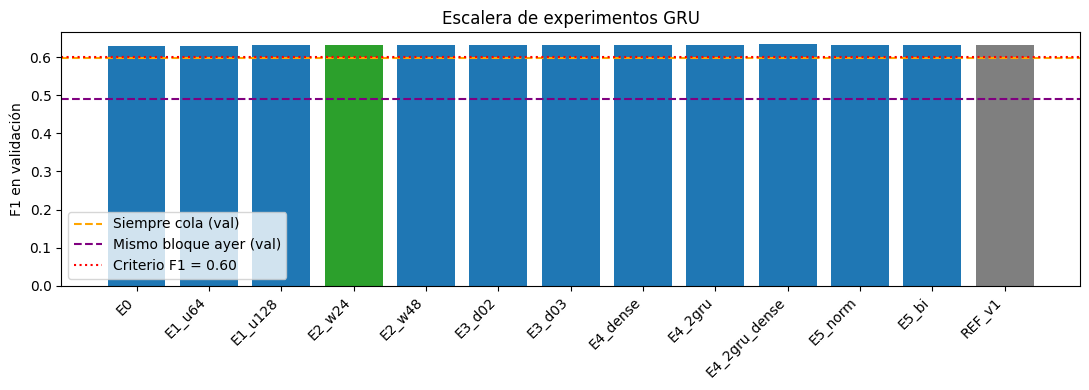

In [25]:
res = pd.DataFrame(RESULTS)
cols = ["exp_id", "stage", "modelo", "window", "params", "F1_val", "Precision_val", "Recall_val",
        "umbral", "F1_val_05", "MAE_val", "RMSE_val", "brecha", "mejor_epoca", "epocas", "segundos"]
display(res[cols].round(4))
print("Modelo elegido hasta ahora:", best_id, cfg)

fig, ax = plt.subplots(figsize=(11, 4))
colors = ["tab:green" if i == best_id else ("tab:gray" if s == "REF" else "tab:blue")
          for i, s in zip(res["exp_id"], res["stage"])]
ax.bar(res["exp_id"], res["F1_val"], color=colors)
ax.axhline(BASE_VAL.loc["Siempre cola", "F1"], color="orange", ls="--", label="Siempre cola (val)")
ax.axhline(BASE_VAL.loc["Mismo bloque ayer", "F1"], color="purple", ls="--", label="Mismo bloque ayer (val)")
ax.axhline(0.60, color="red", ls=":", label="Criterio F1 = 0.60")
ax.set_ylabel("F1 en validación"); ax.set_title("Escalera de experimentos GRU")
plt.xticks(rotation=45, ha="right"); ax.legend(); plt.tight_layout(); plt.show()

## 13. Evaluación en test

Evalúa en test el ganador de la primera tanda (E0–E5) contra *siempre cola* y *mismo bloque ayer*. Los resultados de test **no se usan para elegir nada**: la selección de E0–E5 (y de E6–E9 si se hacen) se queda con validación.

In [26]:
EVALUAR_TEST = True

if EVALUAR_TEST:
    if best_id not in RUNS:   # si el ganador se cargó del CSV, se vuelve a entrenar con la misma semilla
        RERUN = True; run_experiment(best_id, "FINAL", **cfg); RERUN = False
    data = get_data(cfg["window"]); run = RUNS[best_id]
    p_te = run["model"].predict(data["X_te"], batch_size=1024, verbose=0).ravel()
    m_te = cola_metrics(data["y_te"], (p_te >= run["thr"]).astype(int))
    tabla_test = pd.concat([BASE_TEST, pd.DataFrame({f"GRU ({best_id})": m_te}).T])
    display(tabla_test.round(3))
    print("Umbral (elegido en val):", run["thr"])
    print("MAE test:", round(mean_absolute_error(data["y_te"], p_te), 4),
          "| RMSE test:", round(float(np.sqrt(mean_squared_error(data["y_te"], p_te))), 4))
    print("Matriz de confusión (filas = real, columnas = predicho):")
    print(confusion_matrix(label(data["y_te"]), (p_te >= run["thr"]).astype(int)))

Ventana 24 | horizonte 48: train=125,681 val=26,978 test=26,978 | features=27

===== E2_w24 | gru_u32_l1 | ventana=24 | params=5,889 =====
Epoch 1/50
982/982 - 21s - 21ms/step - loss: 0.0960 - mae: 0.2423 - rmse: 0.3099 - val_loss: 0.1359 - val_mae: 0.3158 - val_rmse: 0.3686
Epoch 2/50
982/982 - 18s - 18ms/step - loss: 0.0916 - mae: 0.2335 - rmse: 0.3027 - val_loss: 0.1345 - val_mae: 0.3126 - val_rmse: 0.3668
Epoch 3/50
982/982 - 18s - 18ms/step - loss: 0.0911 - mae: 0.2324 - rmse: 0.3018 - val_loss: 0.1339 - val_mae: 0.3108 - val_rmse: 0.3659
Epoch 4/50
982/982 - 20s - 20ms/step - loss: 0.0908 - mae: 0.2317 - rmse: 0.3013 - val_loss: 0.1335 - val_mae: 0.3096 - val_rmse: 0.3653
Epoch 5/50
982/982 - 18s - 18ms/step - loss: 0.0905 - mae: 0.2310 - rmse: 0.3008 - val_loss: 0.1331 - val_mae: 0.3085 - val_rmse: 0.3648
Epoch 6/50
982/982 - 17s - 18ms/step - loss: 0.0902 - mae: 0.2304 - rmse: 0.3004 - val_loss: 0.1328 - val_mae: 0.3076 - val_rmse: 0.3644
Epoch 7/50
982/982 - 18s - 18ms/step - 

,F1,Precision,Recall,pct_cola_real
Siempre cola,0.730,0.575,1.000,0.575
Bloque anterior (solo comparable con HORIZON = 1),0.667,0.667,0.667,0.575
Mismo bloque ayer,0.650,0.650,0.649,0.575
GRU (E2_w24),0.762,0.625,0.977,0.575


Umbral (elegido en val): 0.36
MAE test: 0.3183 | RMSE test: 0.3698
Matriz de confusión (filas = real, columnas = predicho):
[[ 2356  9101]
 [  353 15168]]


## 14. Predicción vs. real en una semana (un robot, test)

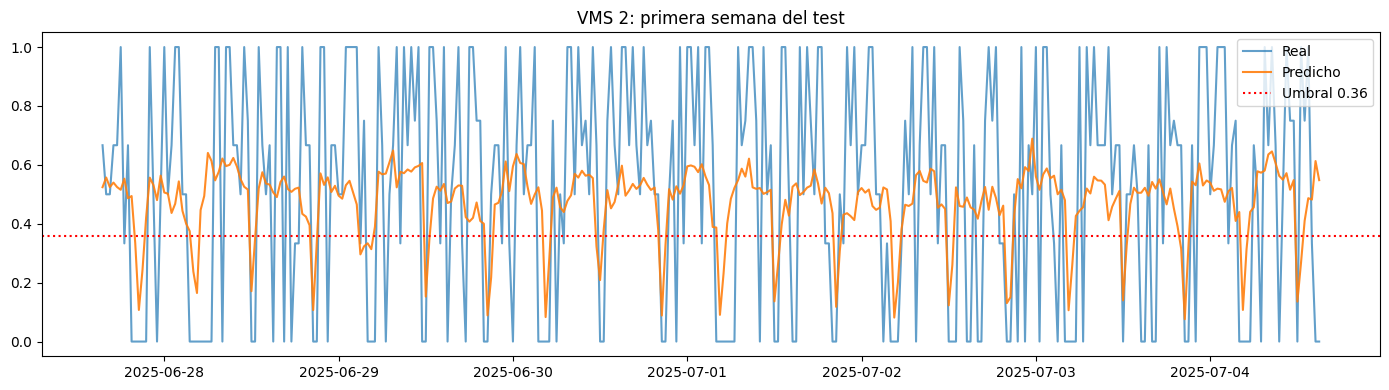

In [27]:
if EVALUAR_TEST:
    m = data["meta_te"].copy()
    m["real"] = data["y_te"]; m["pred"] = p_te
    robot = m["ms"].iloc[0]
    s = m[m["ms"] == robot].head(336)          # 336 bloques = 7 días
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(s["bloque_tiempo"], s["real"], label="Real", alpha=0.7)
    ax.plot(s["bloque_tiempo"], s["pred"], label="Predicho", alpha=0.9)
    ax.axhline(run["thr"], color="red", ls=":", label=f"Umbral {run['thr']:.2f}")
    ax.set_title(f"{robot}: primera semana del test"); ax.legend()
    plt.tight_layout(); plt.show()

## 15. Importancia de variables (por permutación, test)

Desordena una variable a la vez (en todos los pasos de la ventana) y mide cuánto sube el MAE y cuánto baja el F1. Más cambio = más importante. Útil para ver si las variables de lactancia (`pct_fresca`, `pct_alta`, `pct_baja`, `pct_extendida`, `pct_primer_parto`) aportan algo. Se muestrea para que corra rápido.

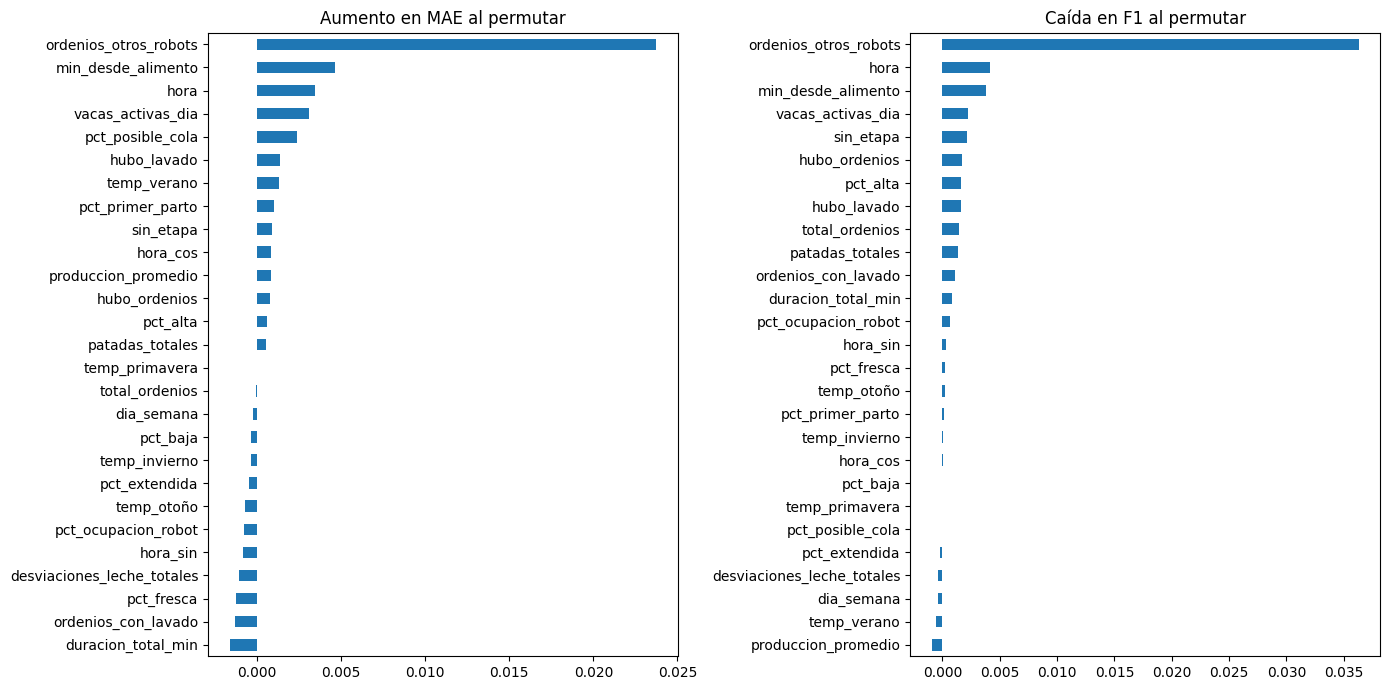

In [28]:
if EVALUAR_TEST:
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(data["X_te"]), size=min(5000, len(data["X_te"])), replace=False)
    Xs, ys = data["X_te"][idx], data["y_te"][idx]
    def _score(X):
        p = run["model"].predict(X, batch_size=1024, verbose=0).ravel()
        return mean_absolute_error(ys, p), cola_metrics(ys, (p >= run["thr"]).astype(int))["F1"]
    mae0, f10 = _score(Xs)
    imp = {}
    for j, name in enumerate(data["prep"].feature_names_):
        Xp = Xs.copy()
        Xp[:, :, j] = Xp[rng.permutation(len(Xs)), :, j]
        mae, f1 = _score(Xp)
        imp[name] = {"aumento_MAE": mae - mae0, "caida_F1": f10 - f1}
    imp = pd.DataFrame(imp).T.sort_values("aumento_MAE")
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    imp["aumento_MAE"].plot.barh(ax=axes[0], title="Aumento en MAE al permutar")
    imp["caida_F1"].sort_values().plot.barh(ax=axes[1], title="Caída en F1 al permutar")
    plt.tight_layout(); plt.show()

## 16. Exportar el modelo

In [29]:
if EVALUAR_TEST:
    import json, joblib
    from pathlib import Path
    # Colab: se guarda en Drive (Datos/Modelos) porque el clon del repo en /content se borra;
    #        de ahí se copia a models/gru/ del repo para hacer commit.
    # Local: se guarda directo en models/gru/ del repo.
    MODELS_DIR = (Path("/content/drive/MyDrive/Datos/Modelos") / "gru") if IN_COLAB else REPO_ROOT / "models" / "gru"
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    # Nombre propio para el modelo del día siguiente: no sobreescribe gru_E2_w48 (siguiente bloque),
    # que todavía usan el servidor del demo y los notebooks de evaluación.
    tag = ("gru_dia_siguiente" if HORIZON == 48 else f"gru_{best_id}_h{HORIZON}" if HORIZON != 1 else f"gru_{best_id}") \
          + ("_quick" if QUICK else "")
    model_file, scaler_file, config_file = (MODELS_DIR / f"{tag}.keras",
                                            MODELS_DIR / f"{tag}_scaler.joblib",
                                            MODELS_DIR / f"{tag}_config.json")
    run["model"].save(model_file)
    joblib.dump(data["prep"].scaler, scaler_file)
    fila = next(r for r in RESULTS if r["exp_id"] == best_id)
    json.dump({
        "exp_id": best_id, "task": "regression", "target": TARGET, **cfg,
        "threshold_label": LABEL_THR, "threshold_decision": run["thr"],
        "feature_names": data["prep"].feature_names_,
        "input_shape": list(data["X_te"].shape[1:]), "shift_target": True,
        "horizon": HORIZON,
        "split": {"train": TRAIN_FRAC, "val": VAL_FRAC, "test": round(1 - TRAIN_FRAC - VAL_FRAC, 2)},
        "metrics_val": {k: fila[k] for k in ["F1_val", "Precision_val", "Recall_val", "MAE_val", "RMSE_val"]},
        "metrics_test": {**m_te, "MAE": float(mean_absolute_error(data["y_te"], p_te))},
    }, open(config_file, "w"), indent=2, ensure_ascii=False, default=float)
    print("Guardado:")
    for p in (model_file, scaler_file, config_file):
        print(" ", p)

Guardado:
  /content/drive/MyDrive/Datos/Modelos/gru/gru_dia_siguiente.keras
  /content/drive/MyDrive/Datos/Modelos/gru/gru_dia_siguiente_scaler.joblib
  /content/drive/MyDrive/Datos/Modelos/gru/gru_dia_siguiente_config.json


## 17. Verificar exportación

In [30]:
if EVALUAR_TEST:
    loaded = tf.keras.models.load_model(model_file)
    p_orig = run["model"].predict(data["X_te"][:1000], verbose=0).ravel()
    p_load = loaded.predict(data["X_te"][:1000], verbose=0).ravel()
    print("Máx. diferencia:", float(np.abs(p_orig - p_load).max()))   # debe ser ~0

Máx. diferencia: 0.0
